# Options Pricing with Neural Networks

**Goal.** Train a neural network to price European call options and compare it with the Black–Scholes model.

The project has two parts:

1. **Learning Black–Scholes.** A network is trained on prices generated by the Black–Scholes formula. Because the true function is known in closed form, this is a controlled test of how accurately a network can learn a pricing function.
2. **Learning a stochastic-volatility model (Heston).** Real option markets show a volatility *smile* that Black–Scholes cannot produce. Here the network is trained on prices from the Heston (1993) model, then compared both with the true Heston price and with Black–Scholes. Its implied-volatility surface is reconstructed and checked for no-arbitrage violations.

**Inputs:** moneyness S/K, time to maturity T, risk-free rate r, and volatility parameters (σ for Black–Scholes; v₀, κ, θ, ξ, ρ for Heston).
**Model:** fully connected network (PyTorch) with a no-arbitrage lower bound built into the output.
**Loss:** mean squared error.

All training data are generated in this notebook from the pricing models themselves, so no external dataset is needed. The Heston pricer is checked against QuantLib's analytic Heston engine before it is used.

References: Hutchinson, Lo & Poggio (1994), *A Nonparametric Approach to Pricing and Hedging Derivative Securities via Learning Networks*; Culkin & Das (2017), *Machine Learning in Finance: The Case of Deep Learning for Option Pricing*; Heston (1993); Albrecher et al. (2007), *The Little Heston Trap*.

## 1. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3D projection)
from scipy.stats import norm
from scipy.optimize import brentq
import torch
import torch.nn as nn
import QuantLib as ql

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("torch", torch.__version__, "| QuantLib", ql.__version__)

torch 2.15.0+cu132 | QuantLib 1.44


## 2. Pricing models

Prices are expressed per unit strike (K = 1, S = moneyness). Because call prices are homogeneous of degree one in (S, K), this removes one input without loss of generality.

### 2.1 Black–Scholes

In [2]:
def bs_call(m, T, r, sigma):
    """Black-Scholes call price per unit strike. m = S/K."""
    m, T, r, sigma = map(np.asarray, (m, T, r, sigma))
    sqrtT = np.sqrt(T)
    d1 = (np.log(m) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    d2 = d1 - sigma * sqrtT
    return m * norm.cdf(d1) - np.exp(-r * T) * norm.cdf(d2)


def bs_implied_vol(price, m, T, r):
    """Implied volatility by Brent's method; NaN if the price is outside no-arbitrage bounds."""
    lower = max(m - np.exp(-r * T), 0.0)
    if not (lower + 1e-10 < price < m):
        return np.nan
    return brentq(lambda s: bs_call(m, T, r, s) - price, 1e-4, 5.0, xtol=1e-10)

### 2.2 Heston model

Under Heston, the variance follows a mean-reverting square-root process:

$$dS_t = rS_t\,dt + \sqrt{v_t}S_t\,dW^S_t,\qquad dv_t = \kappa(\theta - v_t)\,dt + \xi\sqrt{v_t}\,dW^v_t,\qquad d\langle W^S, W^v\rangle_t = \rho\,dt.$$

Call prices come from the characteristic function of $\ln S_T$, written in the numerically stable "little trap" form of Albrecher et al. (2007). The two probability integrals are evaluated with Gauss–Legendre quadrature, vectorised over options.

In [3]:
GL_X, GL_W = np.polynomial.legendre.leggauss(400)
U_MAX = 300.0
U_NODES = 0.5 * U_MAX * (GL_X + 1.0)   # map [-1, 1] -> [0, U_MAX]
U_WEIGHTS = 0.5 * U_MAX * GL_W


def _heston_cf(u, m, T, r, v0, kappa, theta, xi, rho):
    """Characteristic function of ln S_T (S_0 = m), little-trap formulation. u: (n_nodes,), params: (n, 1)."""
    iu = 1j * u
    a = kappa - rho * xi * iu
    d = np.sqrt(a**2 + xi**2 * (iu + u**2))
    g = (a - d) / (a + d)
    edT = np.exp(-d * T)
    C = (kappa * theta / xi**2) * ((a - d) * T - 2.0 * np.log((1.0 - g * edT) / (1.0 - g)))
    D = ((a - d) / xi**2) * (1.0 - edT) / (1.0 - g * edT)
    return np.exp(iu * (np.log(m) + r * T) + C + D * v0)


def heston_call(m, T, r, v0, kappa, theta, xi, rho, chunk=20000):
    """Heston call price per unit strike (K = 1), vectorised over options."""
    arrs = [np.atleast_1d(np.asarray(a, dtype=float)) for a in (m, T, r, v0, kappa, theta, xi, rho)]
    n = max(len(a) for a in arrs)
    arrs = [np.broadcast_to(a, (n,)) for a in arrs]
    out = np.empty(n)
    u = U_NODES[None, :]
    for s in range(0, n, chunk):
        p = [a[s:s + chunk, None] for a in arrs]
        mm, TT, rr = p[0], p[1], p[2]
        phi = _heston_cf(u, *p)
        phi_shift = _heston_cf(u - 1j, *p)
        fwd = mm * np.exp(rr * TT)                     # = phi(-i)
        # ln K = 0 because K = 1
        integrand_p2 = np.real(phi / (1j * u))
        integrand_p1 = np.real(phi_shift / (1j * u * fwd))
        P2 = 0.5 + (integrand_p2 @ U_WEIGHTS) / np.pi
        P1 = 0.5 + (integrand_p1 @ U_WEIGHTS) / np.pi
        out[s:s + chunk] = mm[:, 0] * P1 - np.exp(-rr[:, 0] * TT[:, 0]) * P2
    return out

### 2.3 Check the Heston pricer against QuantLib

Before generating any training data, the implementation is compared with QuantLib's `AnalyticHestonEngine` on 300 randomly drawn contracts.

In [4]:
def quantlib_heston_call(m, T, r, v0, kappa, theta, xi, rho):
    today = ql.Date(2, 1, 2024)
    ql.Settings.instance().evaluationDate = today
    dc = ql.Actual365Fixed()
    maturity = today + ql.Period(int(round(T * 365)), ql.Days)
    T_exact = dc.yearFraction(today, maturity)
    spot = ql.QuoteHandle(ql.SimpleQuote(m))
    rate = ql.YieldTermStructureHandle(ql.FlatForward(today, r, dc))
    div = ql.YieldTermStructureHandle(ql.FlatForward(today, 0.0, dc))
    process = ql.HestonProcess(rate, div, spot, v0, kappa, theta, xi, rho)
    engine = ql.AnalyticHestonEngine(ql.HestonModel(process), 1e-10, 10000)
    option = ql.VanillaOption(ql.PlainVanillaPayoff(ql.Option.Call, 1.0), ql.EuropeanExercise(maturity))
    option.setPricingEngine(engine)
    return option.NPV(), T_exact


HESTON_RANGES = dict(m=(0.7, 1.3), T=(0.1, 2.0), r=(0.0, 0.06), v0=(0.01, 0.16),
                     kappa=(0.5, 4.0), theta=(0.01, 0.16), xi=(0.1, 0.8), rho=(-0.9, 0.0))

def sample_params(ranges, n, rng):
    return pd.DataFrame({k: rng.uniform(lo, hi, n) for k, (lo, hi) in ranges.items()})

check = sample_params(HESTON_RANGES, 300, np.random.default_rng(7))
ql_prices, T_exact = zip(*[quantlib_heston_call(*row) for row in check.itertuples(index=False)])
check["T"] = T_exact                      # use QuantLib's day-count maturity for a like-for-like comparison
ours = heston_call(*[check[c].values for c in HESTON_RANGES])
abs_err = np.abs(ours - np.array(ql_prices))
print(f"Max |ours - QuantLib| over 300 contracts: {abs_err.max():.2e}   (mean {abs_err.mean():.2e})")
assert abs_err.max() < 1e-6, "Heston pricer disagrees with QuantLib"

Max |ours - QuantLib| over 300 contracts: 3.51e-10   (mean 1.64e-12)


## 3. Neural-network pricer

The network predicts the **time value** of the option and adds it to the intrinsic lower bound $\max(S/K - e^{-rT}, 0)$. A softplus output keeps the time value non-negative, so every prediction respects that no-arbitrage bound by construction. Inputs are standardised using training-set statistics. The output layer starts with a small time value: with default initialisation the first predictions are far above typical prices, and in testing the Heston network then stalled at a high loss.

In [5]:
class OptionPricer(nn.Module):
    def __init__(self, n_inputs, hidden=128, depth=4):
        super().__init__()
        layers, d = [], n_inputs
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        layers += [nn.Linear(d, 1)]
        self.net = nn.Sequential(*layers)
        # Start with a small time value (softplus(-3) ≈ 0.05). With default initialisation the output
        # starts near 0.7, far above typical prices, and training on the Heston data stalls.
        with torch.no_grad():
            self.net[-1].bias.fill_(-3.0)
            self.net[-1].weight.mul_(0.1)
        self.register_buffer("mu", torch.zeros(n_inputs))
        self.register_buffer("sd", torch.ones(n_inputs))

    def forward(self, x_raw):
        # x_raw columns: m, T, r, ... (first three are always moneyness, maturity, rate)
        m, T, r = x_raw[:, 0], x_raw[:, 1], x_raw[:, 2]
        lower = torch.clamp(m - torch.exp(-r * T), min=0.0)
        time_value = nn.functional.softplus(self.net((x_raw - self.mu) / self.sd).squeeze(-1))
        return lower + time_value


def train_pricer(X_tr, y_tr, X_va, y_va, epochs=80, batch=1024, lr=1e-3, patience=10, verbose_every=10):
    X_tr_t, y_tr_t = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)
    X_va_t, y_va_t = torch.tensor(X_va, dtype=torch.float32), torch.tensor(y_va, dtype=torch.float32)
    model = OptionPricer(X_tr.shape[1])
    model.mu.copy_(X_tr_t.mean(0)); model.sd.copy_(X_tr_t.std(0))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    loss_fn = nn.MSELoss()
    history, best, best_state, wait = [], np.inf, None, 0
    n = len(X_tr_t)
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n)
        running = 0.0
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(X_tr_t[idx]), y_tr_t[idx])
            loss.backward()
            opt.step()
            running += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_va_t), y_va_t).item()
        sched.step(val)
        history.append((epoch, running / n, val))
        if val < best - 1e-12:
            best, best_state, wait = val, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
        if epoch % verbose_every == 0 or epoch == 1:
            print(f"epoch {epoch:3d}  train MSE {running / n:.3e}  val MSE {val:.3e}  lr {opt.param_groups[0]['lr']:.1e}")
        if wait >= patience:
            print(f"early stop at epoch {epoch}")
            break
    model.load_state_dict(best_state)
    print(f"training time {time.time() - t0:.0f}s, best val MSE {best:.3e}")
    return model, pd.DataFrame(history, columns=["epoch", "train_mse", "val_mse"])


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32)).numpy().astype(float)


def metrics(y_true, y_pred):
    err = y_pred - y_true
    ss_res, ss_tot = np.sum(err**2), np.sum((y_true - y_true.mean())**2)
    return {"RMSE": np.sqrt(np.mean(err**2)), "MAE": np.mean(np.abs(err)),
            "Max abs error": np.max(np.abs(err)), "R²": 1 - ss_res / ss_tot}


def split(n, rng, frac=(0.8, 0.1, 0.1)):
    idx = rng.permutation(n)
    a, b = int(frac[0] * n), int((frac[0] + frac[1]) * n)
    return idx[:a], idx[a:b], idx[b:]

## 4. Part A: learning Black–Scholes

200,000 contracts are drawn uniformly over S/K ∈ [0.7, 1.3], T ∈ [0.05, 2] years, r ∈ [0, 6%] and σ ∈ [5%, 60%], then split 80/10/10 into train, validation and test sets.

In [6]:
BS_RANGES = dict(m=(0.7, 1.3), T=(0.05, 2.0), r=(0.0, 0.06), sigma=(0.05, 0.6))
N_BS = 200_000
bs_df = sample_params(BS_RANGES, N_BS, rng)
bs_df["price"] = bs_call(bs_df.m, bs_df["T"], bs_df.r, bs_df.sigma)
bs_df.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
m,200000.0,1.0000,0.1732,0.70,0.8496,1.0001,1.1498,1.3000
T,200000.0,1.0243,0.5627,0.05,0.5363,1.0240,1.5122,2.0000
r,200000.0,0.0300,0.0173,0.00,0.0150,0.0299,0.0449,0.0600
sigma,200000.0,0.3254,0.1588,0.05,0.1876,0.3255,0.4632,0.6000
price,200000.0,0.1617,0.1229,0.00,0.0528,0.1452,0.2551,0.5777


In [7]:
X_bs = bs_df[list(BS_RANGES)].values
y_bs = bs_df["price"].values
tr, va, te = split(N_BS, rng)
bs_model, bs_hist = train_pricer(X_bs[tr], y_bs[tr], X_bs[va], y_bs[va])

epoch   1  train MSE 7.970e-04  val MSE 8.002e-05  lr 1.0e-03


epoch  10  train MSE 1.485e-06  val MSE 1.348e-06  lr 1.0e-03


epoch  20  train MSE 3.470e-07  val MSE 3.225e-07  lr 1.0e-03


epoch  30  train MSE 1.744e-07  val MSE 1.792e-07  lr 5.0e-04


epoch  40  train MSE 1.274e-07  val MSE 1.267e-07  lr 2.5e-04


epoch  50  train MSE 1.128e-07  val MSE 9.912e-08  lr 2.5e-04


epoch  60  train MSE 9.477e-08  val MSE 1.012e-07  lr 2.5e-04


epoch  70  train MSE 7.827e-08  val MSE 7.402e-08  lr 1.3e-04


epoch  80  train MSE 7.388e-08  val MSE 7.359e-08  lr 1.3e-04
training time 42s, best val MSE 6.997e-08


In [8]:
bs_pred_te = predict(bs_model, X_bs[te])
bs_metrics = metrics(y_bs[te], bs_pred_te)
pd.Series(bs_metrics, name="Black–Scholes test set (per unit strike)").to_frame().style.format("{:.2e}")

,Black–Scholes test set (per unit strike)
RMSE,2.67e-04
MAE,1.66e-04
Max abs error,2.36e-03
R²,1.00e+00


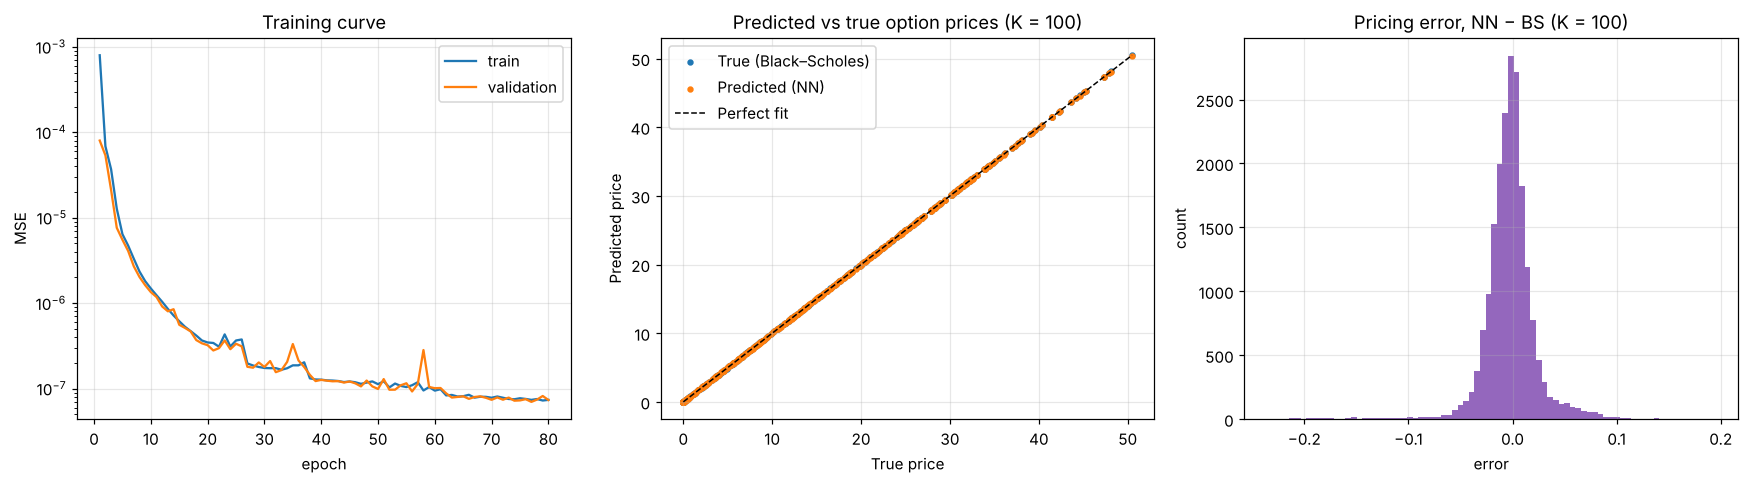

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ax = axes[0]
ax.semilogy(bs_hist.epoch, bs_hist.train_mse, label="train")
ax.semilogy(bs_hist.epoch, bs_hist.val_mse, label="validation")
ax.set(title="Training curve", xlabel="epoch", ylabel="MSE"); ax.legend()

ax = axes[1]
sub = rng.choice(len(te), 400, replace=False)
K_PLOT = 100.0   # show prices for a strike of 100 to make the axis readable
ax.scatter(y_bs[te][sub] * K_PLOT, y_bs[te][sub] * K_PLOT, s=10, c="tab:blue", label="True (Black–Scholes)")
ax.scatter(y_bs[te][sub] * K_PLOT, bs_pred_te[sub] * K_PLOT, s=10, c="tab:orange", label="Predicted (NN)")
lim = [0, (y_bs[te][sub] * K_PLOT).max()]
ax.plot(lim, lim, "k--", lw=1, label="Perfect fit")
ax.set(title="Predicted vs true option prices (K = 100)", xlabel="True price", ylabel="Predicted price"); ax.legend()

ax = axes[2]
ax.hist((bs_pred_te - y_bs[te]) * K_PLOT, bins=80, color="tab:purple")
ax.set(title="Pricing error, NN − BS (K = 100)", xlabel="error", ylabel="count")
plt.tight_layout(); plt.show()

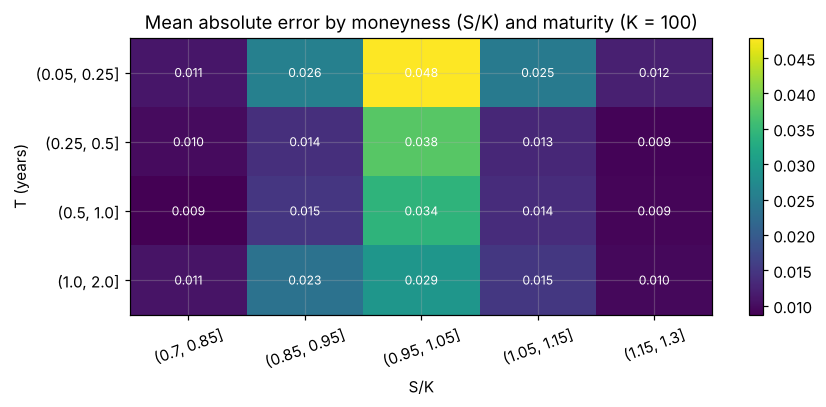

In [10]:
err_df = pd.DataFrame({"m": X_bs[te, 0], "T": X_bs[te, 1], "abs_err": np.abs(bs_pred_te - y_bs[te]) * K_PLOT})
err_df["moneyness"] = pd.cut(err_df.m, [0.7, 0.85, 0.95, 1.05, 1.15, 1.3])
err_df["maturity"] = pd.cut(err_df["T"], [0.05, 0.25, 0.5, 1.0, 2.0])
heat = err_df.pivot_table(index="maturity", columns="moneyness", values="abs_err", aggfunc="mean", observed=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(heat.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(heat.shape[1]), [str(c) for c in heat.columns], rotation=20)
ax.set_yticks(range(heat.shape[0]), [str(i) for i in heat.index])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
ax.set(title="Mean absolute error by moneyness (S/K) and maturity (K = 100)", xlabel="S/K", ylabel="T (years)")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 5. Part B: learning the Heston model

200,000 contracts are drawn with eight inputs: S/K, T, r, initial variance v₀, mean-reversion speed κ, long-run variance θ, volatility of variance ξ, and spot–variance correlation ρ (ranges are listed in `HESTON_RANGES`). A handful of draws can fall outside the no-arbitrage bounds because of quadrature error at extreme parameters, so prices are screened for these before training.

In [11]:
N_H = 200_000
h_df = sample_params(HESTON_RANGES, N_H, rng)
t0 = time.time()
h_df["price"] = heston_call(*[h_df[c].values for c in HESTON_RANGES])
gen_time = time.time() - t0
lower = np.maximum(h_df.m - np.exp(-h_df.r * h_df["T"]), 0)
valid = np.isfinite(h_df.price) & (h_df.price >= lower - 1e-8) & (h_df.price <= h_df.m)
print(f"Generated {N_H:,} Heston prices in {gen_time:.1f}s; {(~valid).sum()} removed by the bounds check")
h_df = h_df[valid].reset_index(drop=True)

Generated 200,000 Heston prices in 41.8s; 18 removed by the bounds check


In [12]:
H_COLS = list(HESTON_RANGES)
X_h, y_h = h_df[H_COLS].values, h_df["price"].values
tr_h, va_h, te_h = split(len(h_df), rng)
h_model, h_hist = train_pricer(X_h[tr_h], y_h[tr_h], X_h[va_h], y_h[va_h], epochs=120, patience=12, verbose_every=20)

epoch   1  train MSE 4.139e-04  val MSE 6.189e-05  lr 1.0e-03


epoch  20  train MSE 4.101e-07  val MSE 4.152e-07  lr 1.0e-03


epoch  40  train MSE 1.220e-07  val MSE 1.218e-07  lr 5.0e-04


epoch  60  train MSE 7.713e-08  val MSE 8.043e-08  lr 1.3e-04


epoch  80  train MSE 6.701e-08  val MSE 6.852e-08  lr 6.3e-05


epoch 100  train MSE 6.170e-08  val MSE 6.547e-08  lr 3.1e-05


epoch 120  train MSE 5.882e-08  val MSE 6.174e-08  lr 1.6e-05
training time 64s, best val MSE 6.174e-08


### 5.1 Neural network vs Black–Scholes on Heston prices

How much does ignoring stochastic volatility cost? For each test contract, Black–Scholes is run with two common volatility choices: the current volatility √v₀, and the volatility implied by the contract's expected average variance over its life, $\bar\sigma^2 = \theta + (v_0-\theta)\frac{1-e^{-\kappa T}}{\kappa T}$. The second is the strongest constant-volatility benchmark available without seeing the price. Both are compared with the network's prediction against the true Heston price.

In [13]:
test = h_df.iloc[te_h].copy()
test["nn"] = predict(h_model, X_h[te_h])
kT = test.kappa * test["T"]
test["avg_var"] = test.theta + (test.v0 - test.theta) * (1 - np.exp(-kT)) / kT
test["bs_spot_vol"] = bs_call(test.m, test["T"], test.r, np.sqrt(test.v0))
test["bs_avg_vol"] = bs_call(test.m, test["T"], test.r, np.sqrt(test.avg_var))

comparison = pd.DataFrame({
    "Neural network": metrics(test.price.values, test.nn.values),
    "Black–Scholes, σ = √v₀": metrics(test.price.values, test.bs_spot_vol.values),
    "Black–Scholes, σ = expected average vol": metrics(test.price.values, test.bs_avg_vol.values),
}).T
(comparison[["RMSE", "MAE", "Max abs error"]] * 100).round(4).assign(**{"R²": comparison["R²"].round(6)}) \
    .rename(columns=lambda c: c if c == "R²" else f"{c} (K = 100)")

,RMSE (K = 100),MAE (K = 100),Max abs error (K = 100),R²
Neural network,0.0246,0.0165,0.2227,0.999995
"Black–Scholes, σ = √v₀",2.5267,1.7595,12.8838,0.949835
"Black–Scholes, σ = expected average vol",0.6607,0.4351,5.7795,0.996570


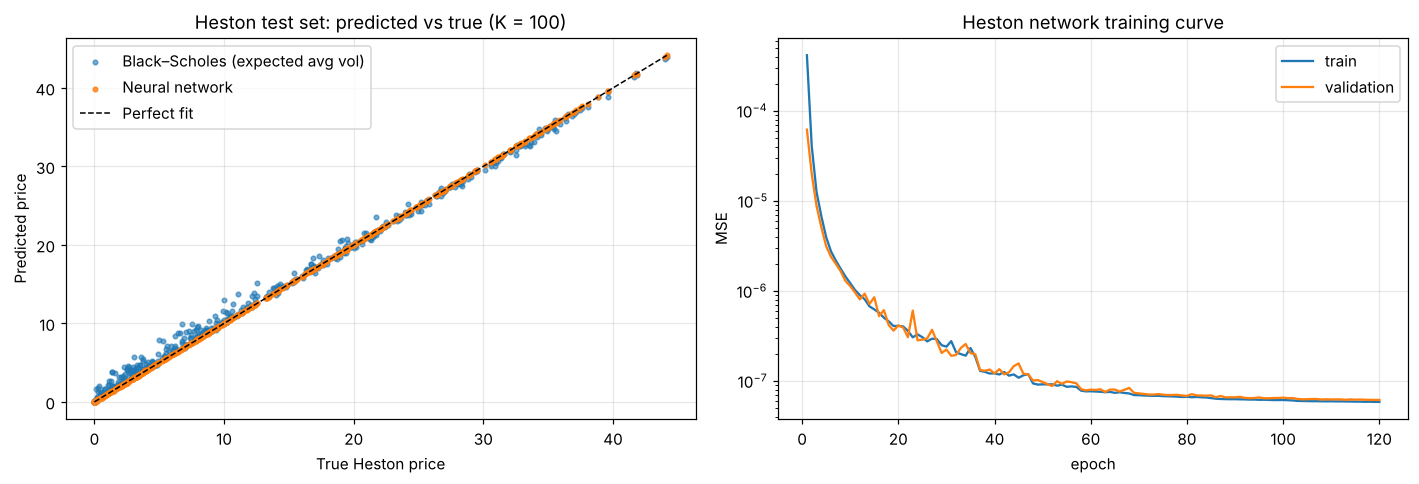

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
sub = rng.choice(len(test), 500, replace=False)
t = test.iloc[sub]
ax.scatter(t.price * 100, t.bs_avg_vol * 100, s=9, alpha=0.6, label="Black–Scholes (expected avg vol)")
ax.scatter(t.price * 100, t.nn * 100, s=9, alpha=0.8, label="Neural network")
lim = [0, t.price.max() * 100]
ax.plot(lim, lim, "k--", lw=1, label="Perfect fit")
ax.set(title="Heston test set: predicted vs true (K = 100)", xlabel="True Heston price", ylabel="Predicted price"); ax.legend()

ax = axes[1]
ax.semilogy(h_hist.epoch, h_hist.train_mse, label="train")
ax.semilogy(h_hist.epoch, h_hist.val_mse, label="validation")
ax.set(title="Heston network training curve", xlabel="epoch", ylabel="MSE"); ax.legend()
plt.tight_layout(); plt.show()

### 5.2 Implied-volatility surface

For one representative parameter set, typical of equity-index calibrations (strongly negative ρ, which produces a downward skew), prices are computed on a grid of strikes and maturities with both the network and the exact Heston formula, then converted to Black–Scholes implied volatilities. A flat surface would mean Black–Scholes is adequate. The skew shows what it misses.

In [15]:
surf_params = dict(r=0.03, v0=0.04, kappa=1.5, theta=0.05, xi=0.6, rho=-0.7)
strikes = np.linspace(80, 140, 31)          # spot fixed at 100
maturities = np.linspace(0.15, 1.9, 25)
KK, TT = np.meshgrid(strikes, maturities)
m_grid = 100.0 / KK
grid = np.column_stack([m_grid.ravel(), TT.ravel()] + [np.full(KK.size, surf_params[k]) for k in ["r", "v0", "kappa", "theta", "xi", "rho"]])

nn_px = predict(h_model, grid)
true_px = heston_call(*grid.T)
iv_nn = np.array([bs_implied_vol(p, mm, T, surf_params["r"]) for p, mm, T in zip(nn_px, grid[:, 0], grid[:, 1])]).reshape(KK.shape)
iv_true = np.array([bs_implied_vol(p, mm, T, surf_params["r"]) for p, mm, T in zip(true_px, grid[:, 0], grid[:, 1])]).reshape(KK.shape)
iv_err_bp = (iv_nn - iv_true) * 1e4
print(f"Implied-vol error (NN − Heston) over the grid: mean abs {np.nanmean(np.abs(iv_err_bp)):.1f} bp, "
      f"max abs {np.nanmax(np.abs(iv_err_bp)):.1f} bp; {np.isnan(iv_nn).sum()} grid points without a valid NN implied vol")

Implied-vol error (NN − Heston) over the grid: mean abs 22.5 bp, max abs 484.2 bp; 0 grid points without a valid NN implied vol


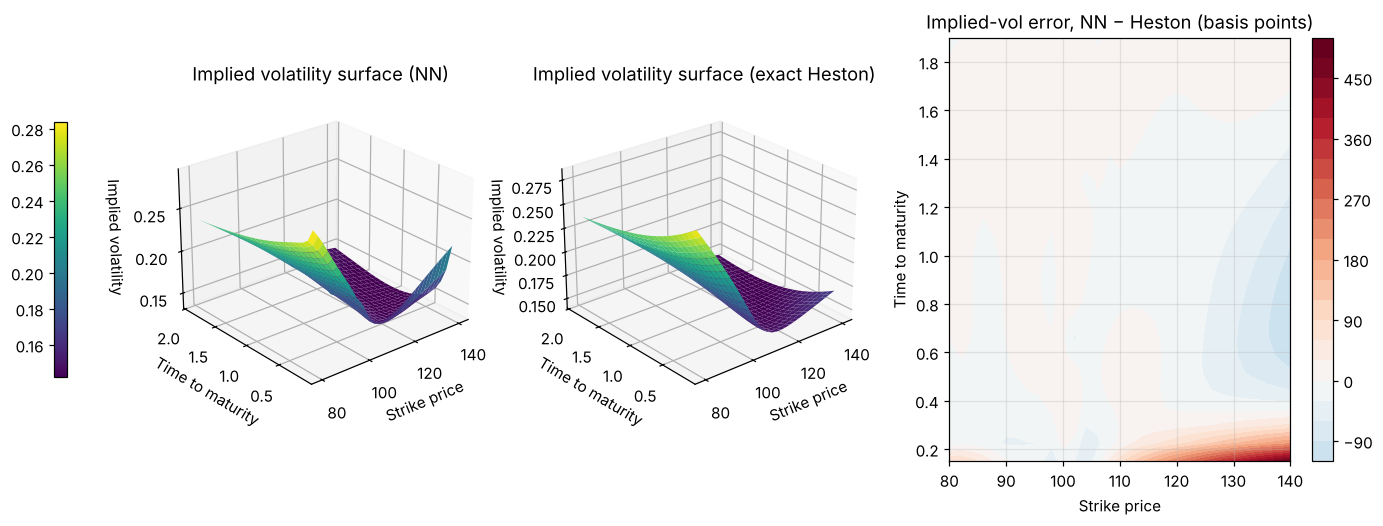

In [16]:
fig = plt.figure(figsize=(17, 5))
for i, (Z, title) in enumerate([(iv_nn, "Implied volatility surface (NN)"), (iv_true, "Implied volatility surface (exact Heston)")]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    s = ax.plot_surface(KK, TT, Z, cmap="viridis", vmin=np.nanmin(iv_true), vmax=np.nanmax(iv_true), linewidth=0)
    ax.set(title=title, xlabel="Strike price", ylabel="Time to maturity", zlabel="Implied volatility")
    ax.view_init(elev=25, azim=-130)
fig.colorbar(s, ax=fig.axes, shrink=0.6, location="left")
ax = fig.add_subplot(1, 3, 3)
im = ax.contourf(KK, TT, iv_err_bp, levels=21, cmap="RdBu_r", vmin=-np.nanmax(np.abs(iv_err_bp)), vmax=np.nanmax(np.abs(iv_err_bp)))
ax.set(title="Implied-vol error, NN − Heston (basis points)", xlabel="Strike price", ylabel="Time to maturity")
plt.colorbar(im, ax=ax)
plt.show()

### 5.3 No-arbitrage checks on the learned surface

Call prices must be non-increasing and convex in strike, and non-decreasing in maturity (no calendar arbitrage, with zero dividends). These shape constraints are not imposed during training, so they are checked here on the network's price grid. Prices per unit of spot are used to compare across strikes.

In [17]:
C = (nn_px * KK.ravel()).reshape(KK.shape) / 100.0        # call price per unit spot, rows = maturities, cols = strikes
dK = np.diff(C, axis=1)
butterfly = C[:, :-2] - 2 * C[:, 1:-1] + C[:, 2:]
calendar = np.diff(C, axis=0)
tol = 1e-6
checks = pd.DataFrame({
    "constraint": ["decreasing in strike", "convex in strike (butterfly ≥ 0)", "increasing in maturity"],
    "violations": [(dK > tol).sum(), (butterfly < -tol).sum(), (calendar < -tol).sum()],
    "checked": [dK.size, butterfly.size, calendar.size],
})
checks["share"] = (checks.violations / checks.checked).map("{:.2%}".format)
checks

,constraint,violations,checked,share
0,decreasing in strike,0,750,0.00%
1,convex in strike (butterfly ≥ 0),12,725,1.66%
2,increasing in maturity,0,744,0.00%


## 6. Speed

The practical motivation for neural pricers is speed: once trained, one forward pass prices thousands of options. Here the network is timed against the vectorised Heston quadrature used in this notebook and against QuantLib's analytic engine (one contract at a time, as it is normally called).

In [18]:
bench = h_df[H_COLS].values[:20000]
t0 = time.perf_counter(); _ = predict(h_model, bench); t_nn = time.perf_counter() - t0
t0 = time.perf_counter(); _ = heston_call(*bench.T); t_quad = time.perf_counter() - t0
sample_ql = h_df[H_COLS].iloc[:200]
t0 = time.perf_counter()
for row in sample_ql.itertuples(index=False):
    quantlib_heston_call(*row)
t_ql = (time.perf_counter() - t0) / 200 * len(bench)
speed = pd.DataFrame({"seconds for 20,000 options": [t_nn, t_quad, t_ql]},
                     index=["Neural network (batched)", "Heston quadrature (vectorised NumPy)", "QuantLib analytic engine (extrapolated from 200)"])
speed["µs per option"] = speed.iloc[:, 0] / len(bench) * 1e6
speed.round(4)

,"seconds for 20,000 options",µs per option
Neural network (batched),0.0484,2.4192
Heston quadrature (vectorised NumPy),4.2318,211.5917
QuantLib analytic engine (extrapolated from 200),4.3700,218.5011


## 7. Results and discussion

The cells below collect the headline numbers produced by this run.

In [19]:
summary = pd.DataFrame({
    "Black–Scholes network (test)": {**{k: v * 100 for k, v in bs_metrics.items() if k != "R²"}, "R²": bs_metrics["R²"]},
    "Heston network (test)": {**{k: v * 100 for k, v in comparison.loc["Neural network"].items() if k != "R²"}, "R²": comparison.loc["Neural network", "R²"]},
    "Black–Scholes on Heston (expected avg vol)": {**{k: v * 100 for k, v in comparison.loc["Black–Scholes, σ = expected average vol"].items() if k != "R²"}, "R²": comparison.loc["Black–Scholes, σ = expected average vol", "R²"]},
}).T
summary.columns = ["RMSE (K = 100)", "MAE (K = 100)", "Max abs error (K = 100)", "R²"]
summary.round(5)

,RMSE (K = 100),MAE (K = 100),Max abs error (K = 100),R²
Black–Scholes network (test),0.02667,0.01657,0.23595,1.00000
Heston network (test),0.02464,0.01652,0.22275,1.00000
Black–Scholes on Heston (expected avg vol),0.66066,0.43515,5.77954,0.99657


**How to read these results**

* **Part A** shows that a small network can reproduce the Black–Scholes formula across a wide range of inputs. The errors in the table and heat map are in currency units for a strike of 100, and are largest where prices change fastest: short maturities near the money.
* **Part B** is the more meaningful test. When the data come from a stochastic-volatility model, Black–Scholes with even a well-chosen constant volatility misprices systematically, because it cannot produce a skew. The network learns the Heston pricing function directly from its eight inputs, and the comparison table quantifies the gap.
* The **implied-volatility surface** reconstructed from network prices reproduces the Heston skew. The error map shows where the approximation is weakest, typically at short maturities and away from the money, where implied volatility is very sensitive to small price errors.
* The **no-arbitrage checks** show how often the learned surface breaks shape constraints that were not imposed during training. Enforcing them through architecture or loss penalties (for example, Dugas et al. 2009; Ackerer et al. 2020) is a natural extension.

**Limitations.** All prices are model-generated: the network learns Heston, not the market. Applying this to real quotes would require calibrated parameters or direct training on market data, with bid–ask noise and sparse strikes. Accuracy is only guaranteed inside the sampled parameter ranges, and dividends and American exercise are not covered.

In [20]:
print("Environment:", {"numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__, "QuantLib": ql.__version__})

Environment: {'numpy': '2.5.3', 'pandas': '3.0.5', 'torch': '2.15.0+cu132', 'QuantLib': '1.44'}
